<a href="https://colab.research.google.com/github/ashwinkck/SME-1-/blob/main/upes/CNLP/upes_CNLP05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



1.   Load a text corpus
2.   Tokenize the sentences



3.   Count individual words.
4.   Generate bigram
5.   calculate prob
6.   Prediction of the word
7. apply smoothing to handle unseen words

In [1]:
!pip install -q pandas matplotlib

In [2]:
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# creating our dataset
corpus = [
    "I love natural language processing",
    "i love machine learning",
    "i study natural language processing",
    "i study machine learning",
    "i love artificial intelligence",
    "i study artificial intelligence"
]
print("Total sentences:",len(corpus))

for sentence in corpus:
  print(sentence)

Total sentences: 6
I love natural language processing
i love machine learning
i study natural language processing
i study machine learning
i love artificial intelligence
i study artificial intelligence


In [4]:
print(type(corpus))
print(type(corpus[0]))
print(corpus[0])

<class 'list'>
<class 'str'>
I love natural language processing


In [5]:
# Tokenization
tokenized_sentences = []

for sentence in corpus:
  words = sentence.lower().split()

  tokenized_sentences.append(words)

print(tokenized_sentences)

[['i', 'love', 'natural', 'language', 'processing'], ['i', 'love', 'machine', 'learning'], ['i', 'study', 'natural', 'language', 'processing'], ['i', 'study', 'machine', 'learning'], ['i', 'love', 'artificial', 'intelligence'], ['i', 'study', 'artificial', 'intelligence']]


In [6]:
# unigram language model
unigram_counts = Counter()
for sentence in tokenized_sentences:
  unigram_counts.update(sentence)
print("Unigram Counts:")

for word, count in unigram_counts.items():
  print(word,":",count)

Unigram Counts:
i : 6
love : 3
natural : 2
language : 2
processing : 2
machine : 2
learning : 2
study : 3
artificial : 2
intelligence : 2


In [7]:
#calculating the unigram prob

total_words = sum(unigram_counts.values())
unigram_probabilites = {}
for word, count in unigram_counts.items():
  probability = count/total_words
  unigram_probabilites[word] = probability
print("Total word tokens:",total_words)

for word, probability in unigram_probabilites.items():
  print(word,":",round(probability,3))

Total word tokens: 26
i : 0.231
love : 0.115
natural : 0.077
language : 0.077
processing : 0.077
machine : 0.077
learning : 0.077
study : 0.115
artificial : 0.077
intelligence : 0.077


In [8]:
# bigram language model
bigram_counts = Counter()
context_counts = Counter()

for sentence in tokenized_sentences:
  for i in range(len(sentence)-1):
    first_word = sentence[i]
    second_word = sentence[i+1]

    bigram_counts[(first_word, second_word)]+=1
    context_counts[first_word]+=1
  print("Bigram counts:")

  for bigram, count in bigram_counts.items():
    print(bigram,":",count)

Bigram counts:
('i', 'love') : 1
('love', 'natural') : 1
('natural', 'language') : 1
('language', 'processing') : 1
Bigram counts:
('i', 'love') : 2
('love', 'natural') : 1
('natural', 'language') : 1
('language', 'processing') : 1
('love', 'machine') : 1
('machine', 'learning') : 1
Bigram counts:
('i', 'love') : 2
('love', 'natural') : 1
('natural', 'language') : 2
('language', 'processing') : 2
('love', 'machine') : 1
('machine', 'learning') : 1
('i', 'study') : 1
('study', 'natural') : 1
Bigram counts:
('i', 'love') : 2
('love', 'natural') : 1
('natural', 'language') : 2
('language', 'processing') : 2
('love', 'machine') : 1
('machine', 'learning') : 2
('i', 'study') : 2
('study', 'natural') : 1
('study', 'machine') : 1
Bigram counts:
('i', 'love') : 3
('love', 'natural') : 1
('natural', 'language') : 2
('language', 'processing') : 2
('love', 'machine') : 1
('machine', 'learning') : 2
('i', 'study') : 2
('study', 'natural') : 1
('study', 'machine') : 1
('love', 'artificial') : 1
('a

In [10]:
# calculate bigram prob using MLE

bigram_probabilities = {}

for bigram, count in bigram_counts.items():

    first_word = bigram[0]

    probability = count / context_counts[first_word]

    bigram_probabilities[bigram] = probability

print("Bigram probabilities:")

for bigram, probability in bigram_probabilities.items():

    print(bigram, ":", round(probability, 3))


Bigram probabilities:
('i', 'love') : 0.5
('love', 'natural') : 0.333
('natural', 'language') : 1.0
('language', 'processing') : 1.0
('love', 'machine') : 0.333
('machine', 'learning') : 1.0
('i', 'study') : 0.5
('study', 'natural') : 0.333
('study', 'machine') : 0.333
('love', 'artificial') : 0.333
('artificial', 'intelligence') : 1.0
('study', 'artificial') : 0.333


In [11]:

vocabulary = set()

for sentence in tokenized_sentences:

    vocabulary.update(sentence)

V = len(vocabulary)

print("Vocabulary:", vocabulary)

print("Vocabulary size:", V)


Vocabulary: {'learning', 'machine', 'artificial', 'language', 'love', 'intelligence', 'i', 'natural', 'processing', 'study'}
Vocabulary size: 10


In [12]:

def smoothed_probability(first_word, second_word):

    bigram_count = bigram_counts[(first_word, second_word)]

    context_count = context_counts[first_word]

    probability = (
        bigram_count + 1
    ) / (
        context_count + V
    )

    return probability


In [13]:

print(
    "Without smoothing:",
    bigram_counts[("love", "learning")]
    / context_counts["love"]
)

print(
    "With smoothing:",
    smoothed_probability("love", "learning")
)


Without smoothing: 0.0
With smoothing: 0.07692307692307693


In [14]:

def predict_next_word(word):

    candidates = []

    for bigram, probability in bigram_probabilities.items():

        first_word, next_word = bigram

        if first_word == word:

            candidates.append((next_word, probability))

    if not candidates:

        return "No prediction available"

    candidates.sort(
        key=lambda item: item[1],
        reverse=True
    )

    return candidates[0][0]


In [15]:

def predict_next_words(word):

    candidates = []

    for next_word in vocabulary:

        probability = smoothed_probability(
            word,
            next_word
        )

        candidates.append((next_word, probability))

    candidates.sort(
        key=lambda item: item[1],
        reverse=True
    )

    return candidates


predictions = predict_next_words("love")

for word, probability in predictions[:5]:

    print(word, ":", round(probability, 4))


machine : 0.1538
artificial : 0.1538
natural : 0.1538
learning : 0.0769
language : 0.0769


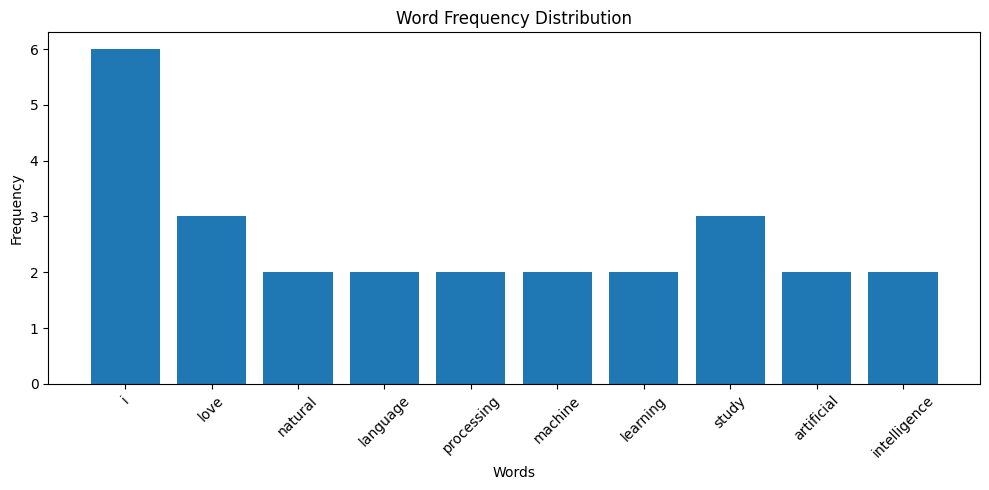

In [16]:

words = list(unigram_counts.keys())

frequencies = list(unigram_counts.values())

plt.figure(figsize=(10, 5))

plt.bar(words, frequencies)

plt.xlabel("Words")

plt.ylabel("Frequency")

plt.title("Word Frequency Distribution")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


In [20]:

# ============================================
# DAY 07: STATISTICAL LANGUAGE MODEL
# NEXT-WORD PREDICTION SYSTEM
# ============================================

# 1. IMPORT LIBRARIES

from collections import Counter

# 2. PREPARE CORPUS

corpus = [
    "i love natural language processing",
    "i love machine learning",
    "i study natural language processing",
    "i study machine learning",
    "i love artificial intelligence",
    "i study artificial intelligence"
]

# 3. TOKENIZATION

tokenized_sentences = [
    sentence.lower().split()
    for sentence in corpus
]

# 4. UNIGRAM COUNTS

unigram_counts = Counter()

for sentence in tokenized_sentences:
    unigram_counts.update(sentence)

total_words = sum(unigram_counts.values())

# 5. BIGRAM COUNTS

bigram_counts = Counter()
context_counts = Counter()

for sentence in tokenized_sentences:

    for i in range(len(sentence) - 1):

        first_word = sentence[i]
        second_word = sentence[i + 1]

        bigram_counts[(first_word, second_word)] += 1
        context_counts[first_word] += 1

# 6. BIGRAM PROBABILITIES

bigram_probabilities = {}

for bigram, count in bigram_counts.items():

    first_word = bigram[0]

    probability = count / context_counts[first_word]

    bigram_probabilities[bigram] = probability

# 7. VOCABULARY

vocabulary = set()

for sentence in tokenized_sentences:
    vocabulary.update(sentence)

V = len(vocabulary)

# 8. LAPLACE SMOOTHING

def smoothed_probability(first_word, second_word):

    bigram_count = bigram_counts[(first_word, second_word)]

    context_count = context_counts[first_word]

    return (bigram_count + 1) / (context_count + V)


# 9. NEXT-WORD PREDICTION

def predict_next_words(word):

    candidates = []

    if word not in context_counts:
        return []

    for next_word in vocabulary:

        probability = smoothed_probability(
            word,
            next_word
        )

        candidates.append((next_word, probability))

    candidates.sort(
        key=lambda item: item[1],
        reverse=True
    )

    return candidates


# 10. USER INPUT

input_word = input("Enter a word: ").lower().strip()

predictions = predict_next_words(input_word)

# 11. DISPLAY RESULTS

if predictions:

    print("\nPossible next words:")

    for word, probability in predictions[:5]:

        print(
            word,
            "->",
            round(probability, 4)
        )

else:

    print("No prediction available for this context.")


Enter a word: i

Possible next words:
love -> 0.25
study -> 0.25
learning -> 0.0625
machine -> 0.0625
artificial -> 0.0625
